In [1]:
from evaluation_utils import *
RESULTS_PATH = os.path.join(RESULTS_DIR, "mc_maze_sac_sparse")

/export/home/nemonds/miniconda/envs/hier-mtf/lib/python3.13/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:///" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in best_trial.params.keys():
    print(
        f"  {param} imp: {param_importances.get(param, tc.nan):.4f}, best: {best_trial.params.get(param)}")
#remove_pruned_trial_folders(study, RESULTS_PATH)

## Evaluation

In [3]:
from src.models.mtf_sac_model import MTF_SAC_Model
from src.main import init_dataset
GOAL_STATE = [0.0, 0.0]
T_DYNAMICS = 1
T_CONTROL = 80
RUN = "001"
DEVICE = tc.device("cpu")

In [5]:
# load test set
measurement2_go_cues = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/externals/go_cue_trials.pkl", allow_pickle=True)
measurement2_target_position = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/externals/target_position_trials.pkl", allow_pickle=True)
measurement2_spike_trials = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/observations/1_spikes_trials.pkl", allow_pickle=True)
measurement2_hand_position_trials = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/observations/2_hand_position_trials.pkl", allow_pickle=True)
measurement2_eye_position_trials = np.load(DATA_DIR + "/mc_maze_preprocessed/measurement2_no_barriers/observations/3_eye_position_trials.pkl", allow_pickle=True)

externals_test = [tc.tensor(np.stack([measurement2_go_cues[time_series_index],
                                     measurement2_target_position[time_series_index][:, 0],
                                     measurement2_target_position[time_series_index][:, 1]], axis=1)).float() for time_series_index in range(len(measurement2_go_cues))]
observations_test = [tc.tensor(np.concatenate([measurement2_spike_trials[time_series_index],
                                              measurement2_hand_position_trials[time_series_index],
                                              measurement2_eye_position_trials[time_series_index]], axis=1)).float() for time_series_index in range(len(measurement2_spike_trials))]

In [6]:
trial = get_trial_by_number(study.trials, 263)
trial_folder_name = "params_" + \
    "_".join([(f"{key}={ValueFormatter._formatted_value(value)}")
             for key, value in trial.params.items()])

In [7]:
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)

parameters = json.load(open(f"{run_path}/config.json"))
mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
dataset = init_dataset(mtf_parameters, DEVICE)
model = MTF_SAC_Model(dataset, model_path=run_path, device=DEVICE) 

Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230
SAC model parameters: 252606


In [8]:
rewards = tc.zeros((6, min(500, len(measurement2_eye_position_trials))))

tc.manual_seed(1)
for k, run in enumerate(["001", "002", "003", "004", "005", "006"]):
    run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)
    parameters = json.load(open(f"{run_path}/config.json"))
    mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
    dataset = init_dataset(mtf_parameters, DEVICE)
    model = MTF_SAC_Model(dataset, model_path=run_path, device=DEVICE)
        
    for time_series_index in range(min(500, len(measurement2_eye_position_trials))):
        (trajectory,
        latent_trajectory,
        actions,
        decoded_actions,
        _,
        _,
        _,
        _) = model.generate_free_trajectory(
            tc.cat([observations_test[time_series_index][0].unsqueeze(0), tc.zeros((T_CONTROL-1, observations_test[time_series_index].shape[1]))], dim=0),
            tc.tensor(range(1)).to(DEVICE),  # One trajectory per subject
            0,
            S=tc.cat([externals_test[time_series_index], externals_test[time_series_index][-1].repeat([T_CONTROL - externals_test[time_series_index].shape[0], 1])]),

            expected=True,
            apply_actions=True
        )
        rewards[k, time_series_index] = model.reward_function(latent_trajectory[:, :-1], actions, 0, expected=True).squeeze()[15:].mean().item()

Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230
SAC model parameters: 252606
Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230
SAC model parameters: 252606
Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230
SAC model parameters: 252606
Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230
SAC model parameters: 252606
Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230
SAC model parameters: 252606
Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230
SAC model parameters: 252606


In [ ]:
rewards.mean(axis=1).mean(), rewards.mean(axis=1).std()

(tensor(-0.0121), tensor(0.0030))

## Analysis

In [10]:
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)

parameters = json.load(open(f"{run_path}/config.json"))
mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
dataset = init_dataset(mtf_parameters, DEVICE)
model = MTF_SAC_Model(dataset, model_path=run_path, device=DEVICE) 

Sequence length set to 40.
Encoder model parameters: 44659
DSR model parameters: 44727
Decoder model parameters: 4230
SAC model parameters: 252606


In [ ]:
trajectories_test = []
trajectories_test_with_actions = []
decoded_actions_test = []
actions_test = []
latent_trajectories_test_with_actions = []
latent_trajectories_test = []

for time_series_index in range(min(500, len(measurement2_eye_position_trials))):
    (trajectory,
    latent_trajectory,
    actions,
    decoded_actions,
    _,
    _,
    _,
    _) = model.generate_free_trajectory(
        tc.cat([observations_test[time_series_index][0].unsqueeze(0), tc.zeros((T_CONTROL-1, observations_test[time_series_index].shape[1]))], dim=0),
        tc.tensor(range(1)).to(DEVICE),  # One trajectory per subject
        0,
        S=tc.cat([externals_test[time_series_index], externals_test[time_series_index][-1].repeat([T_CONTROL - externals_test[time_series_index].shape[0], 1])]),

        expected=True,
        apply_actions=True
    )

    trajectories_test_with_actions.append(trajectory[0, :-1].detach().cpu())
    actions_test.append(actions.detach().cpu())
    decoded_actions_test.append(decoded_actions[0].detach().cpu())
    latent_trajectories_test_with_actions.append(latent_trajectory[0].detach().cpu())
    
for time_series_index in range(min(500, len(measurement2_eye_position_trials))):
    (trajectory,
    latent_trajectory,
    _,
    _,
    _,
    _,
    _,
    _) = model.generate_free_trajectory(
        tc.cat([observations_test[time_series_index][0].unsqueeze(0), tc.zeros((T_CONTROL-1, observations_test[time_series_index].shape[1]))], dim=0),
        tc.tensor(range(1)).to(DEVICE),  
        0,
        S=tc.cat([externals_test[time_series_index], tc.zeros_like(externals_test[time_series_index][-1].repeat([T_CONTROL - externals_test[time_series_index].shape[0], 1]))]),
        expected=True,
        apply_actions=False
    )
    trajectories_test.append(trajectory[0, :-1].detach().cpu())
    latent_trajectories_test.append(latent_trajectory[0].detach().cpu())

In [ ]:
indices_lsr, all_lsr_no_actions = compute_actived_linear_subregions(tc.cat([latent_trajectories_test[i] for i in range(len(latent_trajectories_test))]), model.dsr_model.hyperparameters["relu_units"])
print(all_lsr_no_actions.shape)
hist, _ = np.histogram(indices_lsr.numpy(), bins=np.arange(all_lsr_no_actions.shape[0]+1)-0.5, density=False)
# determine how many lsr are necessary to cover 95% of the controlled time steps
sorted_hist = np.sort(hist)[::-1]
cumsum = np.cumsum(sorted_hist)
n_lsr_90 = np.argwhere(cumsum >= 0.90 * cumsum[-1])[0][0] + 1
print(n_lsr_90)

indices_lsr, all_lsr_with_actions = compute_actived_linear_subregions(tc.cat([latent_trajectories_test_with_actions[i] for i in range(len(latent_trajectories_test_with_actions))]), model.dsr_model.hyperparameters["relu_units"])
print(all_lsr_with_actions.shape)
hist, _ = np.histogram(indices_lsr.numpy(), bins=np.arange(all_lsr_with_actions.shape[0]+1)-0.5, density=False)
# determine how many lsr are necessary to cover 95% of the controlled time steps
sorted_hist = np.sort(hist)[::-1]
cumsum = np.cumsum(sorted_hist)
n_lsr_90 = np.argwhere(cumsum >= 0.90 * cumsum[-1])[0][0] + 1
print(n_lsr_90)

all_lsr, _ = tc.unique(tc.cat([all_lsr_with_actions, all_lsr_no_actions], dim=0), dim=0, return_inverse=True)
print(all_lsr.shape)

torch.Size([578, 20])
125
torch.Size([356, 20])
55
torch.Size([808, 20])


In [19]:
policy_params = model.dsr_sac_model.sac_construct_params(0, model.dsr_sac_model.policy_params, "policy")
latent_step_params = model.dsr_model.construct_params(cumulative_timeseries_index = 0)
relu_units =  model.dsr_model.hyperparameters["relu_units"]
    
fp_lsr = []    
for i, lsr in enumerate(all_lsr):
    for k in range(700):
        state = tc.randn(209)*2
        state[-relu_units:][lsr] = tc.abs(state[-relu_units:][lsr])
        state[-relu_units:][~lsr] = -tc.abs(state[-relu_units:][~lsr])
    
        latent_action, ll = model.dsr_sac_model.sample_action(tc.cat([state, tc.zeros(3)], dim=-1).unsqueeze(0), policy_params, 0, expected=False)
        latent_action = tc.nn.functional.pad(latent_action[0], (0, 209-10))
        remains_in_lsr = ((model.dsr_sac_model.generate_free_trajectory(state.unsqueeze(0)+latent_action, 1, 0, 0, tc.tensor([[[.0,.0, .0]]]), apply_actions=False)[0][0, 1, -relu_units:]>0)    == (state[-relu_units:]>0)).all()
        jacobian = model.dsr_model.latent_step.jacobian(state.unsqueeze(0), latent_step_params, model.dsr_model.hyperparameters)[0]        
        fixed_point = tc.linalg.inv(tc.eye(209) - jacobian)@(latent_step_params["h"][0] + jacobian@latent_action)

        fp_in_lsr = ((fixed_point[-relu_units:]>0)    == (state[-relu_units:]>0)).all()
        decoded_fixed_point = model.decoder_model(fixed_point.unsqueeze(0), 0, expected=True)[0]
        fp_distance = tc.linalg.norm(decoded_fixed_point[-4:-2] - tc.tensor(GOAL_STATE)).cpu().item()**2

        if fp_distance <10 and fp_in_lsr:
            fp_lsr.append([i, fp_distance])
            
fp_lsr = np.array(fp_lsr)

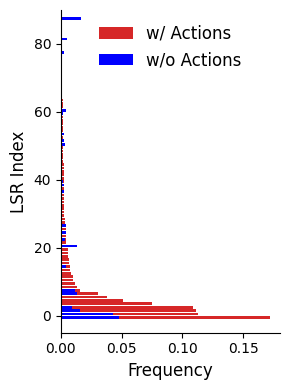

Figure saved to figures_new/sac_maze_hist_lsr_width_27_height_37.pdf


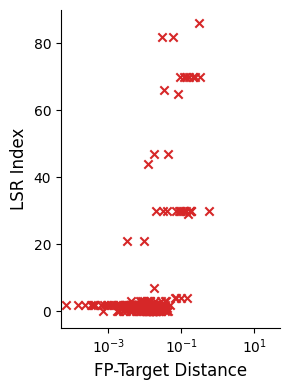

Figure saved to figures_new/sac_maze_fp_distance_width_27_height_37.pdf


In [38]:
# the indices of indices_lsr currently do not match all_lsr, but all_lsr_with_actions. 
# compare all_lsr and all_lsr_with_actions to determine the correct indices for indices_lsr.
indices_lsr, all_lsr_with_actions = compute_actived_linear_subregions(tc.cat([latent_trajectories_test_with_actions[i] for i in range(len(latent_trajectories_test_with_actions))]), model.dsr_model.hyperparameters["relu_units"])
indices_lsr_, all_lsr_with_actions_ = compute_actived_linear_subregions(tc.cat([latent_trajectories_test[i] for i in range(len(latent_trajectories_test))]), model.dsr_model.hyperparameters["relu_units"])

for i in range(len(indices_lsr)):
    index = np.where((all_lsr == all_lsr_with_actions[indices_lsr[i]]).all(dim=1))[0][0]
    indices_lsr[i] = index
    index_ = np.where((all_lsr == all_lsr_with_actions_[indices_lsr_[i]]).all(dim=1))[0][0]
    indices_lsr_[i] = index_
fig2, ax2 = plt.subplots(figsize=(3, 4))
hist, bins = np.histogram(indices_lsr.numpy(), bins=np.arange(all_lsr.shape[0]+1)-0.5)
hist_, bins_ = np.histogram(indices_lsr_.numpy(), bins=np.arange(all_lsr.shape[0]+1)-0.5)
hist = hist/hist.sum()
hist_ = hist_/hist_.sum()
sorting_idx = np.argsort(hist)[::-1]

ax2.barh(bins[:-1], hist[sorting_idx], color='C3')
ax2.barh(bins_[:-1], hist_[sorting_idx], color='blue')
ax2.set_ylabel("LSR Index", fontsize=FONT_SIZE)
ax2.set_xlabel("Frequency", fontsize=FONT_SIZE)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_ylim(-5, 90)
ax2.legend(["w/ Actions", "w/o Actions"], fontsize=FONT_SIZE, frameon=False, ncol=1, loc='upper center')
#ax2.set_yscale("log")
#ax2.set_xlim(0, 0.18)
fig2.tight_layout()
plt.show()
#save_fig(fig2, "sac_maze_hist_lsr")

fig, ax1 = plt.subplots(figsize=(3, 4))
ax1.scatter(fp_lsr[:, 1], [np.argwhere(sorting_idx==a)[0, 0] for a in fp_lsr[:, 0]],c='C3', marker='x')
ax1.set_ylabel("LSR Index", fontsize=FONT_SIZE)
ax1.set_xlabel("FP-Target Distance", fontsize=FONT_SIZE)
ax1.set_ylim(-0.5, all_lsr.shape[0]-0.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_xscale("log")

ax1.set_xlim(0.00005, 50)
ax1.set_ylim(-5, 90)
fig.tight_layout()
plt.show()
#save_fig(fig, "sac_maze_fp_distance")

16


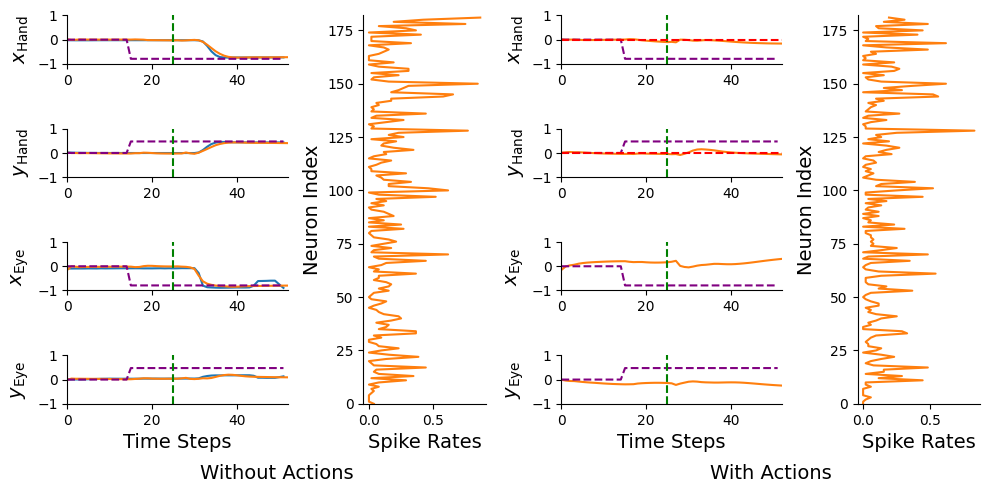

In [ ]:
titles = [r"$x_{\mathrm{Hand}}$", r"$y_{\mathrm{Hand}}$", r"$x_{\mathrm{Eye}}$", r"$y_{\mathrm{Eye}}$"]
ylims = [(-0.5, 0.9), (-0.8, 0.9), (-1.6, 1.9), (-1.25, 1.4)]
time_series_index = 16#64#np.random.randint(len(trajectories_test))
print(time_series_index)

fig = plt.figure(figsize=(10, 5))
# Define a 5x4 GridSpec
gs = GridSpec(
    nrows=5,
    ncols=4,
    height_ratios=[1, 1, 1, 1, 0.2],
    figure=fig,
    width_ratios=[1.8, 1, 1.8, 1]
)

axes_left = []

# Upper block (without actions) - left side (columns 0-1)
for r in range(4):
    ax = fig.add_subplot(gs[r, 0])
    ax.set_xlim(0, observations_test[time_series_index].shape[0])
    ax.plot(observations_test[time_series_index][:, -4 + r])
    ax.plot(trajectories_test[time_series_index][:, -4 + r])
    ax.plot(externals_test[time_series_index][:, r % 2 + 1], color='purple', linestyle='--', label='Target')
    ax.axvline(np.where(externals_test[time_series_index][:, 0] == 1)[0][0], color='g', linestyle='--', label='Go Cue')
    ax.set_ylabel(f"{titles[r]}", fontsize=FONT_SIZE)   
    ax.set_ylim(-1, 1)
    axes_left.append(ax)

# Spikes for upper block (without actions) - right side (column 1)
ax_spikes_1 = fig.add_subplot(gs[:4, 1])  
spikes = model.decoder_model(latent_trajectories_test[time_series_index][:observations_test[time_series_index].shape[0]], 0, expected=False)[:, :182]
ax_spikes_1.set_xlabel('Spike Rates', fontsize=FONT_SIZE)
ax_spikes_1.set_ylabel('Neuron Index', fontsize=FONT_SIZE)
ax_spikes_1.plot(spikes.mean(axis=0), np.arange(182), c="C1")
ax_spikes_1.set_ylim(0, 182)

# Lower block (with actions) - left side (columns 2-3)
for r in range(4):
    ax = fig.add_subplot(gs[r, 2]) # sharey=axes_left[r]
    ax.set_xlim(0, observations_test[time_series_index].shape[0])
    ax.plot(trajectories_test_with_actions[time_series_index][:, -4 + r], c="C1")
    ax.plot(externals_test[time_series_index][:, r % 2 + 1], color='purple', linestyle='--', label='Target')
    ax.axvline(np.where(externals_test[time_series_index][:, 0] == 1)[0][0], color='g', linestyle='--', label='Go Cue')
    ax.set_ylabel(f"{titles[r]}", fontsize=FONT_SIZE)   
    ax.set_ylim(-1, 1)
    axes_left.append(ax)

# Spikes for lower block (with actions) - right side (column 3)
ax_spikes_2 = fig.add_subplot(gs[:4, 3]) 
spikes = model.decoder_model(latent_trajectories_test_with_actions[time_series_index][:observations_test[time_series_index].shape[0]], 0, expected=False)[:, :182]
ax_spikes_2.set_xlabel('Spike Rates', fontsize=FONT_SIZE)
ax_spikes_2.set_ylabel('Neuron Index', fontsize=FONT_SIZE)
ax_spikes_2.plot(tc.clamp(spikes.mean(axis=0), 0, 2), np.arange(182), c="C1")
ax_spikes_2.set_ylim(0, 182)

# Add titles in row 4
ax_title_upper = fig.add_subplot(gs[4, :2])
ax_title_upper.text(0.5, 0.5, 'Without Actions', ha='center', va='center', fontsize=FONT_SIZE)
ax_title_upper.set_axis_off()

ax_title_lower = fig.add_subplot(gs[4, 2:])
ax_title_lower.text(0.5, 0.5, 'With Actions', ha='center', va='center', fontsize=FONT_SIZE)
ax_title_lower.set_axis_off()

# Add goal state lines
axes_left[4].axhline(GOAL_STATE[0], color='r', linestyle='--', label='Goal State')
axes_left[5].axhline(GOAL_STATE[1], color='r', linestyle='--', label='Goal State')

# Add x-labels
axes_left[3].set_xlabel('Time Steps', fontsize=FONT_SIZE)
axes_left[7].set_xlabel('Time Steps', fontsize=FONT_SIZE)

for ax in axes_left + [ax_spikes_1, ax_spikes_2]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()
#save_fig(fig, "mc_maze_sparse_sac_example_trajectories_actions_vs_no_actions")


/tmp/ipykernel_3016626/393813803.py:94: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



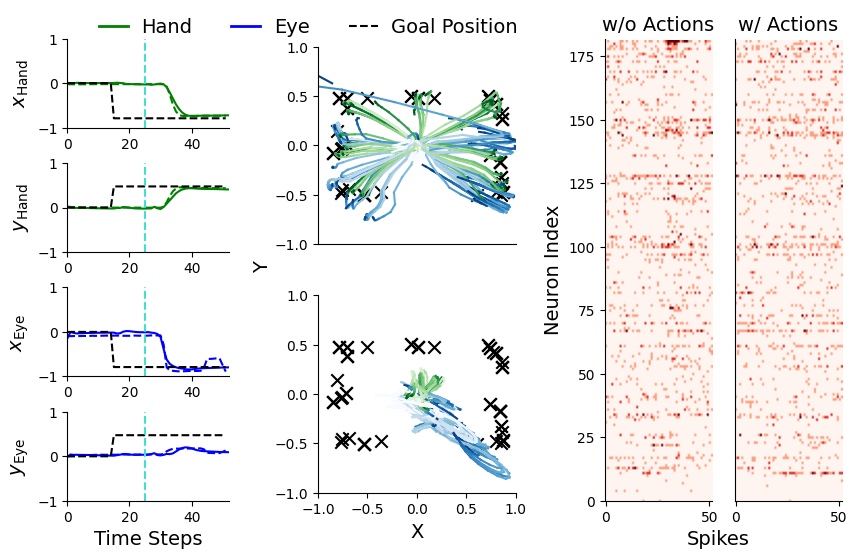

Figure saved to figures_new/mc_maze_sparse_sac_example_trajectories_actions_vs_no_actions_width_83_height_53.pdf


In [ ]:
titles = [r"$x_{\mathrm{Hand}}$", r"$y_{\mathrm{Hand}}$", r"$x_{\mathrm{Eye}}$", r"$y_{\mathrm{Eye}}$"]
ylims = [(-0.5, 0.9), (-0.8, 0.9), (-1.6, 1.9), (-1.25, 1.4)]
time_series_index = 16

fig = plt.figure(figsize=(10, 6))
# Define a 5x4 GridSpec
gs = GridSpec(
    nrows=4,
    ncols=6,
    height_ratios=[1, 1, 1, 1],
    figure=fig,
    width_ratios=[1.8, 0.5,  2.2, 0.5, 1.2, 1.2],
    wspace=0.2,
    hspace=0.4
)

axes_left = []

# Upper block (without actions) - left side (columns 0-1)
for r in range(4):
    ax = fig.add_subplot(gs[r, 0])
    ax.set_xlim(0, observations_test[time_series_index].shape[0])
    ax.plot(observations_test[time_series_index][:, -4 + r],  c="green" if r < 2 else "blue", linestyle='--')
    ax.plot(trajectories_test[time_series_index][:, -4 + r],  c="green" if r < 2 else "blue")
    ax.plot(externals_test[time_series_index][:, r % 2 + 1], color='black', linestyle='--', label='Target')
    ax.axvline(np.where(externals_test[time_series_index][:, 0] == 1)[0][0], color='turquoise', linestyle='--', label='Go Cue')
    ax.set_ylabel(f"{titles[r]}", fontsize=FONT_SIZE)   
    ax.set_ylim(-1, 1)
    axes_left.append(ax)

# Spikes for upper block (without actions) - right side (column 1)
ax_spikes_1 = fig.add_subplot(gs[:4, 4])  
spikes = model.decoder_model(latent_trajectories_test[time_series_index][:observations_test[time_series_index].shape[0]], 0, expected=False)[:, :182]
ax_spikes_1.set_xlabel('Spikes', fontsize=FONT_SIZE, x=1.05)
ax_spikes_1.set_ylabel('Neuron Index', fontsize=FONT_SIZE)
ax_spikes_1.imshow(spikes.T, aspect="auto", cmap='Reds', vmin=0, vmax=3)
ax_spikes_1.set_title("w/o Actions", fontsize=FONT_SIZE)
ax_spikes_1.set_ylim(0, 182)

ax_2d_1 = fig.add_subplot(gs[:2, 2])
ax_2d_2 = fig.add_subplot(gs[2:4, 2])

for time_series_index_ in range(60):    
    for i in range(50):
        ax_2d_1.plot(trajectories_test[time_series_index_][i:i+2, -4 + 0], trajectories_test[time_series_index_][i:i+2, -4 + 1], c=plt.cm.Greens((i/50)**3))
        ax_2d_1.plot(trajectories_test[time_series_index_][i:i+2, -4 + 2], trajectories_test[time_series_index_][i:i+2, -4 + 3], c=plt.cm.Blues((i/50)**3))
        ax_2d_2.plot(trajectories_test_with_actions[time_series_index_][i:i+2, -4 + 0], trajectories_test_with_actions[time_series_index_][i:i+2, -4 + 1], c=plt.cm.Greens((i/50)**3))
        ax_2d_2.plot(trajectories_test_with_actions[time_series_index_][i:i+2, -4 + 2], trajectories_test_with_actions[time_series_index_][i:i+2, -4 + 3], c=plt.cm.Blues((i/50)**3))
    
    # targets
    ax_2d_1.scatter(externals_test[time_series_index_][-1, 1], externals_test[time_series_index_][-1, 2], color='black', marker='x', s=80)
    ax_2d_2.scatter(externals_test[time_series_index_][-1, 1], externals_test[time_series_index_][-1, 2], color='black', marker='x', s=80)

    for ax in [ax_2d_1, ax_2d_2]:
        ax.set_aspect('equal', adjustable='box')
        ax.set_ylim(-1.0, 1.0)
        ax.set_xlim(-1.0, 1.0)
        axes_left.append(ax)
        

ax_2d_2.set_xlabel("X", fontsize=FONT_SIZE)
ax_2d_1.set_xticks([])

from matplotlib.lines import Line2D
# add crosses for the goal state
custom_lines = [Line2D([0], [0], color='green', lw=2),
                Line2D([0], [0], color='blue', lw=2),
                Line2D([0], [0], color='black', markersize=8, linestyle='--')]
# x label
plt.text(0.32, 0.5, 'Y', ha='center', va='center', fontsize=FONT_SIZE, transform=plt.gcf().transFigure, rotation=90)
# make axis 0 the current one
plt.sca(ax_2d_1)
# less space between the items in the legend
plt.legend(custom_lines, ['Hand', 'Eye', 'Goal Position'], fontsize=FONT_SIZE, frameon=False, loc='center left', bbox_to_anchor=(-1.2, 1.1), ncol=3, columnspacing=2, handletextpad=0.7, handlelength=1.5)

# Spikes for lower block (with actions) - right side (column 3)
ax_spikes_2 = fig.add_subplot(gs[:4, 5]) 
spikes = model.decoder_model(latent_trajectories_test_with_actions[time_series_index][:observations_test[time_series_index].shape[0]], 0, expected=False)[:, :182]
ax_spikes_2.imshow(spikes.T, aspect="auto", cmap='Reds', vmin=0, vmax=3)
ax_spikes_2.set_title("w/ Actions", fontsize=FONT_SIZE)
ax_spikes_2.set_ylim(0, 182)
ax_spikes_2.set_yticks([])


# Add x-labels
axes_left[3].set_xlabel('Time Steps', fontsize=FONT_SIZE)

for ax in axes_left + [ax_spikes_1, ax_spikes_2]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
# reduce whitespace the two spike plots
plt.subplots_adjust(wspace=0.1)
plt.tight_layout()
plt.show()
#save_fig(fig, "mc_maze_sparse_sac_example_trajectories_actions_vs_no_actions")

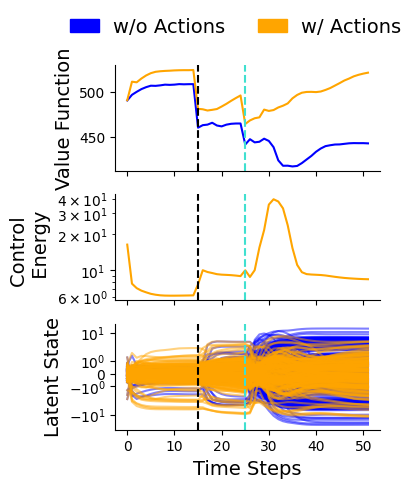

Figure saved to figures_new/mc_maze_sparse_sac_example_value_function_actions_vs_no_actions_width_39_height_46.pdf


In [ ]:
time_series_index = 16

value_function_no_action = compute_value_function(model, latent_trajectories_test[time_series_index][:externals_test[time_series_index].shape[0]], 0, 0, external_inputs=externals_test[time_series_index], n_samples=50)
value_function_with_action = compute_value_function(model, latent_trajectories_test_with_actions[time_series_index][:externals_test[time_series_index].shape[0]], 0, 0, external_inputs=externals_test[time_series_index], n_samples=50)

fig, axs = plt.subplots(3, 1, figsize=(4, 5), sharex=True)
axs[0].plot(value_function_no_action.detach().cpu(), c="blue", label="w/o Actions")
axs[0].plot(value_function_with_action.detach().cpu(), c="orange", label="w/ Actions")
axs[0].set_ylabel("Value Function", fontsize=FONT_SIZE)

axs[1].plot(tc.linalg.norm(decoded_actions_test[time_series_index], ord=2, dim=-1)[:observations_test[time_series_index].shape[0]]**2, c="orange", label="Actions")

axs[1].set_ylabel("Control \n Energy", fontsize=FONT_SIZE)
#axs[1].set_yscale("symlog")
axs[1].set_yscale('log')

axs[2].plot(latent_trajectories_test[time_series_index][:observations_test[time_series_index].shape[0], :], color="blue", alpha=0.5)
axs[2].plot(latent_trajectories_test_with_actions[time_series_index][:observations_test[time_series_index].shape[0], :], color="orange", alpha=0.5)
axs[2].set_xlabel("Time Steps", fontsize=FONT_SIZE)
axs[2].set_ylabel("Latent State", fontsize=FONT_SIZE)
axs[2].set_yscale("symlog")

# common legend over top plot with patches
handles = [plt.Rectangle((0,0),1,1,color=c, label=l) for c,l in zip(["blue", "orange"], ["w/o Actions", "w/ Actions"])]
axs[0].legend(handles=handles, fontsize=FONT_SIZE, frameon=False,  ncol=2, loc=(-0.2, 1.2), columnspacing=1.7, handletextpad=0.7, handlelength=1.5)
for ax in axs:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.axvline(np.where(externals_test[time_series_index][:, 0] == 1)[0][0], color='turquoise', linestyle='--', label='Go Cue')
    ax.axvline(np.where(externals_test[time_series_index][:, 1] != 0)[0][0], color='black', linestyle='--', label='Target X')
plt.tight_layout()
plt.show()
#save_fig(fig, "mc_maze_sparse_sac_example_value_function_actions_vs_no_actions")

In [ ]:
# check if spike rates remain in an plausible regime
# Extract spike data
spike_data_no_action = [model.decoder_model(trajectory[:observations_test[i].shape[0]], 0, expected=False)[:, :182].detach().cpu().numpy() for i, trajectory in enumerate(trajectories_test)]
spike_data_with_action = [model.decoder_model(trajectory[:observations_test[i].shape[0]], 0, expected=False)[:, :182].detach().cpu().numpy() for i, trajectory in enumerate(trajectories_test_with_actions)]

# 1. Mean Spike Rate per neuron across all trials
mean_rate_no_action = np.mean([np.mean(trial, axis=0) for trial in spike_data_no_action], axis=0)
mean_rate_with_action = np.mean([np.mean(trial, axis=0) for trial in spike_data_with_action], axis=0)

# 2. Fano Factor per neuron across all trials
fano_factor_no_action = np.mean([np.var(trial, axis=0) / np.mean(trial, axis=0) for trial in spike_data_no_action], axis=0)
fano_factor_with_action = np.mean([np.var(trial, axis=0) / np.mean(trial, axis=0) for trial in spike_data_with_action], axis=0)

# --- Statistical Tests ---

# Paired t-test for mean spike rates
t_stat_rate, p_value_rate = ttest_rel(mean_rate_no_action, mean_rate_with_action)

# Paired t-test for Fano Factor
t_stat_fano, p_value_fano = ttest_rel(fano_factor_no_action, fano_factor_with_action, nan_policy='omit')

# Print results
print(f"Mean Spike Rate - t-statistic: {t_stat_rate:.4f}, p-value: {p_value_rate:.4f}")
print(f"Fano Factor - t-statistic: {t_stat_fano:.4f}, p-value: {p_value_fano:.4f}")

Mean Spike Rate - t-statistic: -1.3314, p-value: 0.1847
Fano Factor - t-statistic: 1.0410, p-value: 0.3050


/tmp/ipykernel_3869903/1691444410.py:14: RuntimeWarning:

invalid value encountered in divide

/tmp/ipykernel_3869903/1691444410.py:15: RuntimeWarning:

invalid value encountered in divide



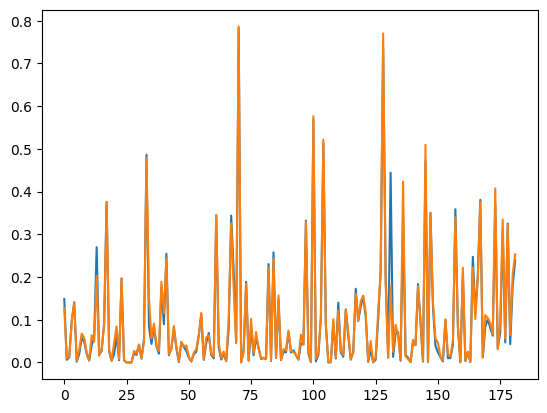

In [ ]:
plt.plot(np.mean([np.mean(trial, axis=0) for trial in spike_data_no_action], axis=0))
plt.plot(np.mean([np.mean(trial, axis=0) for trial in spike_data_with_action], axis=0))

In [ ]:
align_pdf_figures([
    FIG_DIR + "/mc_maze_sparse_sac_example_trajectories_actions_vs_no_actions_width_83_height_53.pdf",
    FIG_DIR + "/mc_maze_sparse_sac_example_value_function_actions_vs_no_actions_width_39_height_46.pdf",
],
    output_pdf="combined_figures5.pdf",
    rows=1,
)

PosixPath('figures_new/combined_figures5.pdf')

In [5]:
align_pdf_figures([
    FIG_DIR + "/sac_maze_hist_lsr_width_27_height_37.pdf",
    FIG_DIR + "/sac_maze_fp_distance_width_27_height_37.pdf",
],
    output_pdf="combined_figures8.pdf",
    rows=1,
    label_fontsize=25,
)

PosixPath('figures_new/combined_figures8.pdf')